# WLASL-100 classical ML baselines (expanded 1,023-video dataset)

This notebook evaluates Logistic Regression, Random Forest, linear SVM, and RBF SVM on the corrected **v2 engineered features** (`wlasl100_landmark_features_v2`) of the expanded WLASL-100 dataset: **1,023 successfully processed videos out of 2,038 metadata instances**. The frozen signer-independent split is read, never regenerated; the expected split sizes are 535 train / 171 validation / 317 test, but all counts are derived and cross-checked from the feature manifest and split metadata at runtime.

Model selection uses signer-grouped CV within the training split only. The primary selection metric is grouped-CV macro-F1 over the **fixed 100-class training label set** (`macro_f1_train_label_set`), with mean accuracy as the tie-breaker. Validation is descriptive; test is held out until after CV selection. Outputs are written to `models/classical/v2/` and `reports/classical/v2/`; the earlier 457-video experiment (`.../v1/`) is not touched.

This notebook is a single-vocabulary (WLASL-100) baseline. It does **not** establish scalability to WLASL-300 or WLASL-2000; those require separate experiments.

## 1. Imports, configuration, and paths

The experiment consumes Notebook 05 v2 raw vectors (`data/processed/WLASL100/features/v2/`). Fold-local pipelines fit imputation, missing-value indicators, and scaling only on each fold’s training portion; the saved Notebook 05 transformers are inspected but are not reused for CV. All models and reports are written to the **v2** output directories; v1 directories are never read from or written to.

In [23]:
from pathlib import Path
import json, os, platform, time, warnings
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, confusion_matrix

# Expected (macro-F1 over fixed labels legitimately predicts classes absent from y_true in sparse folds):
warnings.filterwarnings('ignore', message='y_pred contains classes not in y_true')

PROJECT_DIR=None; RANDOM_SEED=165; N_SPLITS=3; FEATURE_VERSION='wlasl100_landmark_features_v2'; OUTPUT_VERSION='v2'
# Reference values from the project record. They are used ONLY for sanity warnings below;
# every count used in the analysis is derived from the manifest / frozen metadata files.
REFERENCE_COUNTS={'metadata_instances':2038,'processed':1023,'train':535,'val':171,'test':317,'train_classes':100}
SELECTION_METRIC='macro_f1_train_label_set'; SELECTION_TIEBREAK='accuracy'
def root(override=None):
    candidates=([Path(override).expanduser()] if override else [])+[Path.home()/'sign-language-recognition']
    current=Path.cwd().resolve(); candidates += [current,*current.parents]
    for p in candidates:
        if (p.resolve()/'WLASL/start_kit/WLASL_v0.3.json').is_file(): return p.resolve()
    raise FileNotFoundError('Set PROJECT_DIR to project root')
ROOT=root(PROJECT_DIR); DATA=ROOT/'data/processed/WLASL100'; V2=DATA/'features/v2'
MODELS=DATA/'models/classical'/OUTPUT_VERSION; REPORTS=DATA/'reports/classical'/OUTPUT_VERSION
# Guard: inputs must be v2 features, outputs must be classical/v2 (never the previous v1 artifacts).
assert V2.as_posix().endswith('features/v2')
assert MODELS.as_posix().endswith('models/classical/v2') and REPORTS.as_posix().endswith('reports/classical/v2')
MODELS.mkdir(parents=True,exist_ok=True); REPORTS.mkdir(parents=True,exist_ok=True)
print(ROOT, FEATURE_VERSION, sklearn.__version__); print('models ->',MODELS.relative_to(ROOT)); print('reports ->',REPORTS.relative_to(ROOT))

/Users/sahilchauhan/sign-language-recognition wlasl100_landmark_features_v2 1.9.1
models -> data/processed/WLASL100/models/classical/v2
reports -> data/processed/WLASL100/reports/classical/v2


## 2. Load frozen metadata and v2 features

Video IDs are preserved as strings. The feature manifest is joined back to frozen metadata; signer sets must remain disjoint and each split dataset must align exactly by video ID and gloss. Dataset sizes are **derived** from the manifest and cross-checked against the feature summary, the loaded arrays, and the frozen metadata; reference values (535 / 171 / 317, 1,023 processed, 2,038 metadata instances) only trigger warnings if the files disagree. The frozen split files are read only.

Signer accounting: The frozen metadata splits contain 62 training, 15 validation, and 20 test signers. However, due to incomplete video acquisition, only 31, 7, and 12 signers respectively contribute usable videos to the actual experiments. All model training and evaluation statistics use the acquired-video population. The original signer-independent split assignments remain unchanged.

In [24]:
feature_manifest=pd.read_csv(V2/'manifests/feature_manifest.csv',dtype={'video_id':str,'signer_id':str})
summary=json.loads((V2/'feature_extraction_summary.json').read_text())
if summary['feature_version'] != FEATURE_VERSION:
    raise ValueError('Unexpected feature version')

if summary['successfully_processed'] != len(feature_manifest.loc[
    feature_manifest.status.eq('processed')
]):raise ValueError('Feature manifest and summary count mismatch')
def read_frozen():
    parts=[]
    for s in ('train','val','test'):
        d=pd.read_csv(DATA/f'{s}_metadata.csv',dtype={'video_id':str,'signer_id':str}); d['video_id']=d.video_id.str.strip(); d['signer_id']=d.signer_id.astype(str); d['experimental_split']=s; parts.append(d)
    out=pd.concat(parts,ignore_index=True)
    sets={s:set(out.loc[out.experimental_split.eq(s),'signer_id']) for s in ('train','val','test')}
    assert not any(sets[a]&sets[b] for a in sets for b in sets if a<b)
    return out,sets
frozen, signer_sets=read_frozen()
usable=feature_manifest.loc[feature_manifest.status.eq('processed')].copy()
joined=usable.merge(frozen[['video_id','gloss','signer_id','experimental_split']],on='video_id',how='left',suffixes=('','_frozen'),validate='one_to_one')
for c in ('gloss','signer_id','experimental_split'): assert (joined[c].astype(str)==joined[f'{c}_frozen'].astype(str)).all()
def load_split(split):
    # Notebook 05 v2 stores signer_id as an object metadata array; these are local, schema-validated artifacts.
    with np.load(V2/'classical'/f'{split}_dataset.npz',allow_pickle=True) as z:
        data={k:z[k] for k in z.files}
    rows=usable.loc[usable.experimental_split.eq(split)].sort_values('video_id',kind='stable')
    # Dataset was written in manifest order, which is deterministic video-id order.
    assert np.array_equal(data['video_id'].astype(str),rows.video_id.to_numpy())
    assert np.array_equal(data['gloss'].astype(str),rows.gloss.to_numpy())
    assert data['X_raw'].shape[1]==86 and np.array_equal(data['feature_names'],np.array(json.loads((V2/'feature_names.json').read_text())['feature_names']))
    return data['X_raw'],data['gloss'].astype(str),rows.signer_id.to_numpy(),rows.video_id.to_numpy()
X_train,y_train,g_train,id_train=load_split('train'); X_val,y_val,g_val,id_val=load_split('val'); X_test,y_test,g_test,id_test=load_split('test')
print({
    'dataset_shapes': {
        'train': X_train.shape,
        'val': X_val.shape,
        'test': X_test.shape
    },
    'train_classes': len(set(y_train)),

    # All signers in the original frozen metadata splits
    'metadata_signers': {
        split: len(signers)
        for split, signers in signer_sets.items()
    },

    # Only signers whose videos were successfully acquired
    'processed_signers': {
        'train': len(set(g_train)),
        'val': len(set(g_val)),
        'test': len(set(g_test)),
        'total': len(set(g_train) | set(g_val) | set(g_test))
    }
})
# ---- dynamic dataset accounting (derived from files; reference constants only warn) ----
assert usable.experimental_split.isin(['train','val','test']).all()
split_counts={s:int(usable.experimental_split.eq(s).sum()) for s in ('train','val','test')}
array_counts={'train':len(X_train),'val':len(X_val),'test':len(X_test)}
if split_counts!=array_counts: raise ValueError(f'Manifest split counts {split_counts} != loaded arrays {array_counts}')
assert sum(split_counts.values())==len(usable)==summary['successfully_processed']
n_metadata_instances=len(frozen)
train_label_set,val_label_set,test_label_set=set(y_train),set(y_val),set(y_test)
dataset_coverage={'n_metadata_instances_in_frozen_split_files':n_metadata_instances,'n_processed_videos':len(usable),'split_counts':split_counts,
  'n_train_classes':len(train_label_set),'n_val_classes_represented':len(val_label_set),'n_test_classes_represented':len(test_label_set),
  'val_labels_absent_from_train':len(val_label_set-train_label_set),'test_labels_absent_from_train':len(test_label_set-train_label_set),
  'test_examples_with_label_absent_from_train':int(sum(l not in train_label_set for l in y_test)),
  'metadata_signers': {
    'train': len(signer_sets['train']),
    'val': len(signer_sets['val']),
    'test': len(signer_sets['test']),
    'total': len(set().union(*signer_sets.values()))
},

'processed_signers': {
    'train': len(set(g_train)),
    'val': len(set(g_val)),
    'test': len(set(g_test)),
    'total': len(set(g_train) | set(g_val) | set(g_test))
},
  'processed_by_split_vs_metadata_by_split':{s:{'processed':split_counts[s],'metadata':int(frozen.experimental_split.eq(s).sum())} for s in ('train','val','test')}}
ref_actual={'metadata_instances':n_metadata_instances,'processed':len(usable),**split_counts,'train_classes':len(train_label_set)}
for k,v in REFERENCE_COUNTS.items():
    if ref_actual[k]!=v: warnings.warn(f'{k}: derived {ref_actual[k]} differs from reference {v}; analysis uses the derived value')
print(json.dumps(dataset_coverage,indent=1))

{'dataset_shapes': {'train': (535, 86), 'val': (171, 86), 'test': (317, 86)}, 'train_classes': 100, 'metadata_signers': {'train': 62, 'val': 15, 'test': 20}, 'processed_signers': {'train': 31, 'val': 7, 'test': 12, 'total': 50}}
{
 "n_metadata_instances_in_frozen_split_files": 2038,
 "n_processed_videos": 1023,
 "split_counts": {
  "train": 535,
  "val": 171,
  "test": 317
 },
 "n_train_classes": 100,
 "n_val_classes_represented": 91,
 "n_test_classes_represented": 98,
 "val_labels_absent_from_train": 0,
 "test_labels_absent_from_train": 0,
 "test_examples_with_label_absent_from_train": 0,
 "metadata_signers": {
  "train": 62,
  "val": 15,
  "test": 20,
  "total": 97
 },
 "processed_signers": {
  "train": 31,
  "val": 7,
  "test": 12,
  "total": 50
 },
 "processed_by_split_vs_metadata_by_split": {
  "train": {
   "processed": 535,
   "metadata": 1003
  },
  "val": {
   "processed": 171,
   "metadata": 424
  },
  "test": {
   "processed": 317,
   "metadata": 611
  }
 }
}


## 3. Metrics and leakage-safe grouped CV

`GroupKFold` is used (groups = frozen train signer IDs) because many classes have too few examples for a reliable stratified grouped fold; every CV fold is carved from the **training split only**. Imputation and scaling live inside each sklearn `Pipeline`, so they are fitted per CV-training fold. Fold reports explicitly retain missing-class information (labels with zero support in a fold's evaluation portion, and labels missing from a fold's training portion). Two macro-F1 values are computed: over labels present in the evaluation fold (`macro_f1_eval_labels`, diagnostic only; its label set changes between folds) and over the **complete, fixed 100-class training label set** (`macro_f1_train_label_set`, zero-support labels explicitly included and scored 0 via `zero_division=0`). The latter is the primary, fold-comparable selection metric. Because zero-support classes drag it down, its absolute value is conservative; it is used for ranking, not as a headline accuracy.

In [25]:
ALL_TRAIN_LABELS=np.array(sorted(set(y_train)))
def scores(model,X,y,training_labels=ALL_TRAIN_LABELS):
    pred=model.predict(X); classes=np.asarray(model.classes_)
    raw=model.predict_proba(X) if hasattr(model,'predict_proba') else model.decision_function(X)
    raw=np.asarray(raw); raw=raw[:,None] if raw.ndim==1 else raw
    k=min(5,raw.shape[1]); top=classes[np.argsort(raw,axis=1)[:,-k:]]
    top5=np.mean([truth in choices for truth,choices in zip(y,top)])
    eval_labels=np.unique(y); unseen=sorted(set(y)-set(classes))
    return {'accuracy':accuracy_score(y,pred),'macro_f1_eval_labels':f1_score(y,pred,labels=eval_labels,average='macro',zero_division=0),'macro_f1_train_label_set':f1_score(y,pred,labels=training_labels,average='macro',zero_division=0),'weighted_f1':f1_score(y,pred,average='weighted',zero_division=0),'balanced_accuracy':balanced_accuracy_score(y,pred),'top5_accuracy':top5,'n_samples':len(y),'n_eval_classes':len(eval_labels),'n_train_classes':len(classes),'unseen_eval_labels':len(unseen),'n_samples_unseen_true_label':int(sum(t not in set(classes) for t in y)),'n_train_label_set_zero_support':int(len(set(training_labels)-set(eval_labels)))},pred,top
def preprocess(scale=True):
    steps=[('imputer',SimpleImputer(strategy='median',add_indicator=True))]
    if scale: steps.append(('scaler',StandardScaler()))
    return steps
def estimator_specs():
    return {
      'logistic_regression':[({'C':.3,'class_weight':None}),({'C':1.0,'class_weight':'balanced'})],
      'random_forest':[({'n_estimators':250,'max_depth':None,'min_samples_leaf':1,'class_weight':None}),({'n_estimators':250,'max_depth':12,'min_samples_leaf':2,'class_weight':'balanced_subsample'})],
      'linear_svm':[({'C':.3,'class_weight':None}),({'C':1.0,'class_weight':'balanced'})],
      'rbf_svm':[({'C':1.0,'gamma':'scale','class_weight':None}),({'C':3.0,'gamma':'scale','class_weight':'balanced'})]}
def make_model(name,p):
    if name=='logistic_regression': return Pipeline(preprocess()+[('model',LogisticRegression(max_iter=3000,random_state=RANDOM_SEED,**p))])
    if name=='random_forest': return Pipeline(preprocess(False)+[('model',RandomForestClassifier(random_state=RANDOM_SEED,n_jobs=-1,**p))])
    if name=='linear_svm': return Pipeline(preprocess()+[('model',LinearSVC(random_state=RANDOM_SEED,dual='auto',max_iter=5000,**p))])
    if name=='rbf_svm': return Pipeline(preprocess()+[('model',SVC(kernel='rbf',**p))])
    raise KeyError(name)
assert len(ALL_TRAIN_LABELS)==len(train_label_set)
cv=GroupKFold(n_splits=N_SPLITS); folds=list(cv.split(X_train,y_train,g_train))  # training data only; groups = signer IDs
assert sum(len(va) for _,va in folds)==len(X_train)
fold_audit=[]
for i,(tr,va) in enumerate(folds):
    assert not (set(g_train[tr])&set(g_train[va])), 'signer leakage between CV train and eval portions'
    fold_audit.append({'fold':i,'train_samples':len(tr),'eval_samples':len(va),'train_signers':len(set(g_train[tr])),'eval_signers':len(set(g_train[va])),'train_classes':len(set(y_train[tr])),'eval_classes':len(set(y_train[va])),'eval_labels_absent_from_fold_train':len(set(y_train[va])-set(y_train[tr])),'train_label_set_zero_support_in_eval':len(ALL_TRAIN_LABELS)-len(set(y_train[va])),'train_labels_missing_from_fold_train':len(ALL_TRAIN_LABELS)-len(set(y_train[tr]))})
fold_audit=pd.DataFrame(fold_audit); display(fold_audit)

,fold,train_samples,eval_samples,train_signers,eval_signers,train_classes,eval_classes,eval_labels_absent_from_fold_train,train_label_set_zero_support_in_eval,train_labels_missing_from_fold_train
0,0,356,179,20,11,99,93,1,7,1
1,1,357,178,21,10,100,82,0,18,0
2,2,357,178,21,10,100,86,0,14,0


## 4. Train-only grouped CV model selection

The small predetermined candidate grid is deliberately modest. Candidates are ranked by (1) highest mean grouped-CV **macro-F1 over the fixed 100-class training label set** (`macro_f1_train_label_set`), then (2) highest mean accuracy; remaining exact ties fall back to model name and candidate id so the choice is deterministic. `macro_f1_eval_labels` is reported for diagnostics only. Neither validation nor test metrics are used here. Folds may lack some classes in their fold-specific training portions; such folds are kept (not dropped) and the label-set metric still counts those classes.

In [26]:
cv_rows=[]
for name,candidates in estimator_specs().items():
    for candidate_id,params in enumerate(candidates):
        for fold,(tr,va) in enumerate(folds):
            model=make_model(name,params); start=time.perf_counter(); model.fit(X_train[tr],y_train[tr]); fit_seconds=time.perf_counter()-start
            metric,_,_=scores(model,X_train[va],y_train[va]); cv_rows.append({'model':name,'candidate_id':candidate_id,'params_json':json.dumps(params,sort_keys=True),'fold':fold,'fit_seconds':fit_seconds,**metric})
cv_detail=pd.DataFrame(cv_rows); cv_detail.to_csv(REPORTS/'grouped_cv_fold_metrics.csv',index=False)
fold_audit.to_csv(REPORTS/'grouped_cv_fold_audit.csv',index=False)
cv_summary=cv_detail.groupby(['model','candidate_id','params_json']).agg(
    macro_f1_train_label_set_mean=('macro_f1_train_label_set','mean'),macro_f1_train_label_set_std=('macro_f1_train_label_set','std'),
    accuracy_mean=('accuracy','mean'),accuracy_std=('accuracy','std'),
    macro_f1_eval_labels_mean=('macro_f1_eval_labels','mean'),macro_f1_eval_labels_std=('macro_f1_eval_labels','std'),
    top5_mean=('top5_accuracy','mean'),top5_std=('top5_accuracy','std'),fit_seconds_mean=('fit_seconds','mean')).reset_index()
# Selection rule: macro_f1_train_label_set_mean (desc), then accuracy_mean (desc); deterministic final fallback.
cv_summary['_f1_key']=cv_summary.macro_f1_train_label_set_mean.round(12); cv_summary['_acc_key']=cv_summary.accuracy_mean.round(12)
cv_summary=cv_summary.sort_values(['_f1_key','_acc_key','model','candidate_id'],ascending=[False,False,True,True]).drop(columns=['_f1_key','_acc_key']).reset_index(drop=True)
cv_summary.insert(0,'selection_rank',range(1,len(cv_summary)+1))
cv_summary.to_csv(REPORTS/'grouped_cv_summary.csv',index=False); display(cv_summary)
best_params={}
for name in estimator_specs():
    best=cv_summary.loc[cv_summary.model.eq(name)].iloc[0]; best_params[name]=json.loads(best.params_json)
print('selection metric:',SELECTION_METRIC,'| tie-break:',SELECTION_TIEBREAK); print(best_params)

,selection_rank,model,candidate_id,params_json,macro_f1_train_label_set_mean,macro_f1_train_label_set_std,accuracy_mean,accuracy_std,macro_f1_eval_labels_mean,macro_f1_eval_labels_std,top5_mean,top5_std,fit_seconds_mean
0,1,random_forest,1,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.095768,0.019613,0.143891,0.027409,0.110188,0.022678,0.321407,0.044301,0.220571
1,2,random_forest,0,"{""class_weight"": null, ""max_depth"": null, ""min...",0.090167,0.043226,0.112203,0.026002,0.105952,0.056395,0.325236,0.011285,0.210237
2,3,logistic_regression,1,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.085965,0.043762,0.110372,0.050832,0.100255,0.052724,0.345762,0.036911,0.229075
3,4,logistic_regression,0,"{""C"": 0.3, ""class_weight"": null}",0.070530,0.036863,0.095391,0.049095,0.081889,0.043857,0.321491,0.028175,0.232126
4,5,linear_svm,0,"{""C"": 0.3, ""class_weight"": null}",0.069679,0.036214,0.091656,0.031122,0.082039,0.045819,0.286046,0.049467,0.707440
5,6,linear_svm,1,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.069101,0.016461,0.087858,0.006627,0.080379,0.023097,0.295420,0.054608,2.267185
6,7,rbf_svm,1,"{""C"": 3.0, ""class_weight"": ""balanced"", ""gamma""...",0.040863,0.026061,0.061745,0.036911,0.047736,0.030889,0.207520,0.022992,0.022154
7,8,rbf_svm,0,"{""C"": 1.0, ""class_weight"": null, ""gamma"": ""sca...",0.012041,0.007103,0.022430,0.005618,0.013958,0.008378,0.085996,0.006741,0.029332


selection metric: macro_f1_train_label_set | tie-break: accuracy
{'logistic_regression': {'C': 1.0, 'class_weight': 'balanced'}, 'random_forest': {'class_weight': 'balanced_subsample', 'max_depth': 12, 'min_samples_leaf': 2, 'n_estimators': 250}, 'linear_svm': {'C': 0.3, 'class_weight': None}, 'rbf_svm': {'C': 3.0, 'class_weight': 'balanced', 'gamma': 'scale'}}


## 5. Final fitting, descriptive validation, and held-out test

Each selected family is refit once on all training examples (count derived at runtime; expected 535). Validation results are descriptive only: the validation split covers fewer labels than the training split (see the coverage printout in Section 2), so its macro-F1 is based on a partial label set. Test results are recorded after CV selection without further tuning. All test examples are retained in accuracy and top-5 calculations, including any whose true label is absent from the training split (those can never be predicted correctly).

In [27]:
train_label_set=set(y_train)
final_models={}; validation_rows=[]; test_rows=[]; prediction_rows=[]; efficiency=[]
for name,params in best_params.items():
    model=make_model(name,params); start=time.perf_counter(); model.fit(X_train,y_train); train_seconds=time.perf_counter()-start
    final_models[name]=model; joblib.dump(model,MODELS/f'{name}.joblib')
    for split,X,y,ids,collector in [('val',X_val,y_val,id_val,validation_rows),('test',X_test,y_test,id_test,test_rows)]:
        metric,pred,top=scores(model,X,y); collector.append({'model':name,'params_json':json.dumps(params,sort_keys=True),**metric})
        for vid,true,guess,ranked in zip(ids,y,pred,top): prediction_rows.append({'model':name,'split':split,'video_id':vid,'true_gloss':true,'predicted_gloss':guess,'correct':bool(true==guess),'top5_predictions':json.dumps(ranked.tolist()),'label_unseen_in_train':bool(true not in train_label_set)})
    # repeated batch inference, excluding load/plot time
    timings=[]
    for _ in range(10):
        t=time.perf_counter(); model.predict(X_test); timings.append(time.perf_counter()-t)
    file_mb=(MODELS/f'{name}.joblib').stat().st_size/1e6
    core=model.named_steps['model']; complexity=(getattr(core,'n_estimators',None) or getattr(core,'coef_',np.empty((0,))).size or getattr(core,'support_',np.empty(0)).size)
    efficiency.append({'model':name,'train_seconds':train_seconds,'test_batch_latency_mean_seconds':float(np.mean(timings)),'test_batch_latency_median_seconds':float(np.median(timings)),'latency_ms_per_sample':float(np.median(timings)*1000/len(X_test)),'model_size_mb':file_mb,'complexity_proxy':int(complexity)})
validation=pd.DataFrame(validation_rows); test=pd.DataFrame(test_rows); predictions=pd.DataFrame(prediction_rows); efficiency=pd.DataFrame(efficiency)
validation.to_csv(REPORTS/'validation_metrics_descriptive.csv',index=False); test.to_csv(REPORTS/'test_metrics_held_out.csv',index=False); predictions.to_csv(REPORTS/'predictions.csv',index=False); efficiency.to_csv(REPORTS/'efficiency.csv',index=False)
assert (validation.n_samples==len(y_val)).all() and (test.n_samples==len(y_test)).all()  # no test/val example is discarded
assert len(y_test)==split_counts['test'] and len(y_val)==split_counts['val']
display(validation); display(test); display(efficiency)

,model,params_json,accuracy,macro_f1_eval_labels,macro_f1_train_label_set,weighted_f1,balanced_accuracy,top5_accuracy,n_samples,n_eval_classes,n_train_classes,unseen_eval_labels,n_samples_unseen_true_label,n_train_label_set_zero_support
0,logistic_regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.122807,0.090982,0.082794,0.093112,0.138278,0.298246,171,91,100,0,0,9
1,random_forest,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.093567,0.063422,0.057714,0.075299,0.097070,0.309942,171,91,100,0,0,9
2,linear_svm,"{""C"": 0.3, ""class_weight"": null}",0.122807,0.103578,0.094256,0.105784,0.137363,0.315789,171,91,100,0,0,9
3,rbf_svm,"{""C"": 3.0, ""class_weight"": ""balanced"", ""gamma""...",0.081871,0.066143,0.060190,0.070008,0.087912,0.204678,171,91,100,0,0,9


,model,params_json,accuracy,macro_f1_eval_labels,macro_f1_train_label_set,weighted_f1,balanced_accuracy,top5_accuracy,n_samples,n_eval_classes,n_train_classes,unseen_eval_labels,n_samples_unseen_true_label,n_train_label_set_zero_support
0,logistic_regression,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.233438,0.213344,0.209077,0.199143,0.264796,0.482650,317,98,100,0,0,2
1,random_forest,"{""class_weight"": ""balanced_subsample"", ""max_de...",0.264984,0.212067,0.207826,0.219464,0.274830,0.533123,317,98,100,0,0,2
2,linear_svm,"{""C"": 0.3, ""class_weight"": null}",0.249211,0.215221,0.210917,0.219035,0.264286,0.454259,317,98,100,0,0,2
3,rbf_svm,"{""C"": 3.0, ""class_weight"": ""balanced"", ""gamma""...",0.154574,0.126128,0.123605,0.123758,0.183163,0.391167,317,98,100,0,0,2


,model,train_seconds,test_batch_latency_mean_seconds,test_batch_latency_median_seconds,latency_ms_per_sample,model_size_mb,complexity_proxy
0,logistic_regression,0.357746,0.000428,0.000411,0.001296,0.074105,15600
1,random_forest,0.407603,0.027100,0.026105,0.082349,32.674450,250
2,linear_svm,0.634363,0.000653,0.000492,0.001552,0.136773,15600
3,rbf_svm,0.058626,0.016376,0.016337,0.051536,1.649329,535


## 6. Error analysis and plots

The selected model is the candidate ranked first by the training-only CV rule (macro-F1 over the fixed training label set, then accuracy). The test confusion matrix and per-class report use the **complete training label set (`ALL_TRAIN_LABELS`, 100 labels) on both axes**, so classes the model predicts but that have no test ground truth still appear (as all-zero rows with non-zero columns). Consequently the matrix is 100 × 100.

Two reporting distinctions matter here: (i) test examples whose true label is absent from the training split cannot be placed on a training-label row, so they are *not* in the matrix, but they **are** retained in overall accuracy, macro-F1 (as false positives for the class predicted) and top-5 accuracy; their count is saved in `test_label_coverage.json`; (ii) the coverage file separates classes present in training, classes represented in test, test labels absent from training, and predictions made for classes with no test ground truth.

{
 "selected_model": "random_forest",
 "n_training_labels": 100,
 "n_test_labels_represented": 98,
 "n_test_labels_present_in_training": 98,
 "test_labels_absent_from_training": [],
 "n_test_labels_absent_from_training": 0,
 "n_test_examples_total": 317,
 "n_test_examples_with_label_absent_from_training": 0,
 "n_test_examples_in_confusion_matrix": 317,
 "n_training_labels_with_no_test_ground_truth": 2,
 "predicted_classes_without_test_ground_truth": [],
 "n_predictions_on_classes_without_test_ground_truth": 0,
 "confusion_matrix_shape": [
  100,
  100
 ]
}


,precision,recall,f1-score,support,n_predicted,in_test_ground_truth,predicted_without_test_support
accident,0.333333,0.5,0.400000,2.0,3.0,True,False
africa,0.000000,0.0,0.000000,4.0,2.0,True,False
all,0.250000,0.2,0.222222,5.0,4.0,True,False
apple,0.000000,0.0,0.000000,1.0,2.0,True,False
basketball,0.000000,0.0,0.000000,1.0,4.0,True,False


,true_gloss,predicted_gloss,count
0,need,yes,5
1,but,no,3
2,can,jacket,3
3,graduate,work,3
4,fine,white,3
5,who,orange,3
6,hearing,orange,2
7,city,family,2
8,many,clothes,2
9,table,paper,2


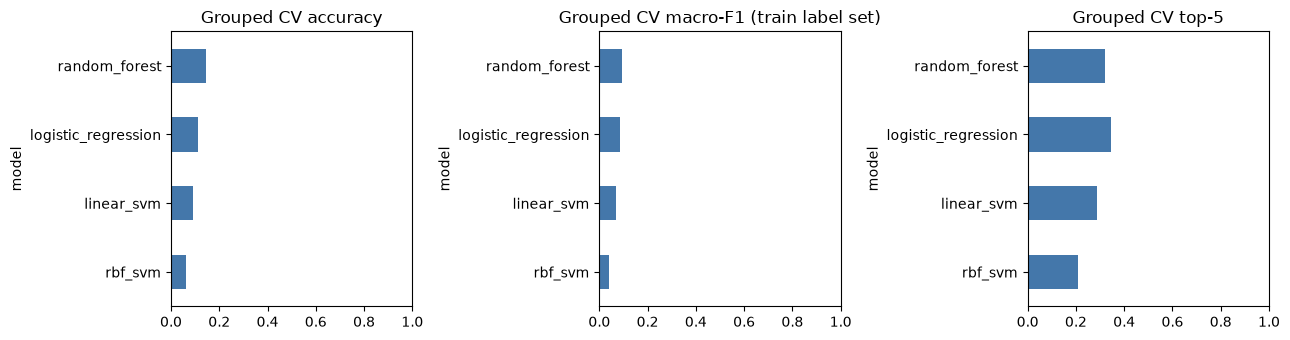

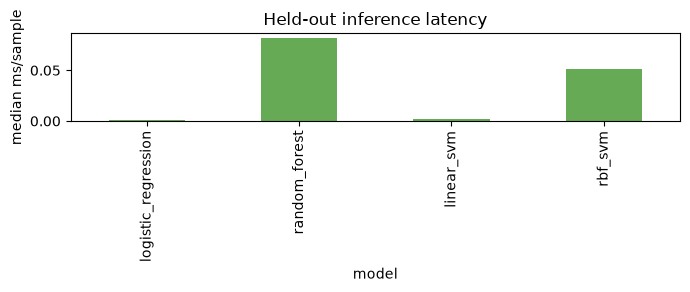

In [28]:
selected=cv_summary.iloc[0].model; model=final_models[selected]; metrics,pred,top=scores(model,X_test,y_test)
assert metrics['n_samples']==len(y_test)==split_counts['test']   # all test examples used in accuracy / top-5
train_label_set=set(ALL_TRAIN_LABELS); test_truth_set=set(y_test); pred_set=set(pred)
known=np.array([label in train_label_set for label in y_test])
assert pred_set<=train_label_set   # model can only predict classes seen in training
# Confusion matrix over the complete training label set on BOTH axes. Rows are test examples with a training-known true label;
# examples with a training-absent true label have no row and are listed in the coverage report instead.
cm=confusion_matrix(y_test[known],pred[known],labels=ALL_TRAIN_LABELS)
assert cm.shape==(len(ALL_TRAIN_LABELS),len(ALL_TRAIN_LABELS))==(100,100) and int(cm.sum())==int(known.sum())
np.save(REPORTS/'selected_model_confusion_matrix.npy',cm)
pd.DataFrame(cm,index=ALL_TRAIN_LABELS,columns=ALL_TRAIN_LABELS).to_csv(REPORTS/'selected_model_confusion_matrix.csv')
# Per-class report over the same 100 labels. All 317 test rows are passed (nothing discarded); zero_division=0.
rep=classification_report(y_test,pred,labels=ALL_TRAIN_LABELS,output_dict=True,zero_division=0); rep.pop('accuracy',None)
report=pd.DataFrame(rep).T
n_pred=pd.Series(pred).value_counts().reindex(ALL_TRAIN_LABELS).fillna(0).astype(int)
report['n_predicted']=n_pred.reindex(report.index); report['in_test_ground_truth']=report['support'].gt(0).where(report.index.isin(ALL_TRAIN_LABELS))
report['predicted_without_test_support']=(report['support'].eq(0)&report['n_predicted'].gt(0)).where(report.index.isin(ALL_TRAIN_LABELS))
assert np.isclose(report.loc['macro avg','f1-score'],metrics['macro_f1_train_label_set'])   # report agrees with the selection-metric definition
report.to_csv(REPORTS/'selected_model_per_class_report.csv')
no_gt_pred=sorted(pred_set-test_truth_set)
test_label_coverage={'selected_model':selected,'n_training_labels':len(ALL_TRAIN_LABELS),'n_test_labels_represented':len(test_truth_set),
  'n_test_labels_present_in_training':len(test_truth_set&train_label_set),'test_labels_absent_from_training':sorted(test_truth_set-train_label_set),
  'n_test_labels_absent_from_training':len(test_truth_set-train_label_set),'n_test_examples_total':int(len(y_test)),
  'n_test_examples_with_label_absent_from_training':int((~known).sum()),'n_test_examples_in_confusion_matrix':int(known.sum()),
  'n_training_labels_with_no_test_ground_truth':len(train_label_set-test_truth_set),
  'predicted_classes_without_test_ground_truth':no_gt_pred,'n_predictions_on_classes_without_test_ground_truth':int(sum(p not in test_truth_set for p in pred)),
  'confusion_matrix_shape':list(cm.shape)}
(REPORTS/'test_label_coverage.json').write_text(json.dumps(test_label_coverage,indent=2)); print(json.dumps(test_label_coverage,indent=1))
# Frequent confusions: only examples whose true label was learnable (present in training); unseen-label errors are tracked in the coverage file.
wrong=predictions.loc[(predictions.model.eq(selected))&(predictions.split.eq('test'))&(~predictions.correct)&(~predictions.label_unseen_in_train)].copy(); pairs=wrong.groupby(['true_gloss','predicted_gloss']).size().sort_values(ascending=False).rename('count').reset_index(); pairs.to_csv(REPORTS/'frequent_confusions.csv',index=False)
display(report.head()); display(pairs.head(10))
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
plot=cv_summary.groupby('model').first()[['accuracy_mean','macro_f1_train_label_set_mean','top5_mean']].sort_values('macro_f1_train_label_set_mean')  # best candidate per family by the selection rule
for ax,col,title in zip(axes,['accuracy_mean','macro_f1_train_label_set_mean','top5_mean'],['Grouped CV accuracy','Grouped CV macro-F1 (train label set)','Grouped CV top-5']): plot[col].plot.barh(ax=ax,color='#4477AA'); ax.set_title(title); ax.set_xlim(0,1)
plt.tight_layout(); plt.savefig(REPORTS/'cv_model_comparison.png',dpi=160); plt.show()
fig,ax=plt.subplots(figsize=(7,3)); efficiency.set_index('model')['latency_ms_per_sample'].plot.bar(ax=ax,color='#66AA55'); ax.set_ylabel('median ms/sample'); ax.set_title('Held-out inference latency'); plt.tight_layout(); plt.savefig(REPORTS/'inference_latency.png',dpi=160); plt.show()

## 7. Save experiment record and research interpretation

Results are baseline estimates for the expanded 1,023-video WLASL-100 subset, subject to acquisition-coverage differences across splits and class sparsity. In particular, grouped folds and the validation/test sets do not contain every training class, and some test labels may be absent from training. **No conclusion about WLASL-300 or WLASL-2000 scaling follows from this notebook**; those require separate experiments. The summary and configuration below are built from values computed in this run.

In [30]:
metadata_signers = {
    'train': len(signer_sets['train']),
    'val': len(signer_sets['val']),
    'test': len(signer_sets['test']),
    'total': len(set().union(*signer_sets.values()))
}

processed_signers = {
    'train': len(set(g_train)),
    'val': len(set(g_val)),
    'test': len(set(g_test)),
    'total': len(set(g_train) | set(g_val) | set(g_test))
}

print("Metadata signers:", metadata_signers)
print("Processed signers:", processed_signers)

Metadata signers: {'train': 62, 'val': 15, 'test': 20, 'total': 97}
Processed signers: {'train': 31, 'val': 7, 'test': 12, 'total': 50}


In [31]:
rel=lambda p: str(Path(p).relative_to(ROOT))
sel_row=cv_summary.iloc[0]; sel_test=test.loc[test.model.eq(selected)].iloc[0].to_dict(); sel_eff=efficiency.loc[efficiency.model.eq(selected)].iloc[0].to_dict()
n_meta=REFERENCE_COUNTS['metadata_instances']
limitations=[f"Only {len(usable):,} of {n_meta:,} WLASL-100 metadata instances have usable videos.",
  "Acquisition coverage differs across splits: processed vs metadata counts per split are recorded in dataset.processed_by_split_vs_metadata_by_split.",
  "Some classes have sparse training support (few examples and few signers).",
f"Test labels absent from training: {dataset_coverage['test_labels_absent_from_train']} classes, covering {dataset_coverage['test_examples_with_label_absent_from_train']} test examples.",  "Grouped CV folds may lack certain classes in their fold-specific training subsets; see grouped_cv_fold_audit.csv.",
  "This experiment does not establish scalability to WLASL-300 or WLASL-2000."]
config={'dataset':'WLASL-100 (expanded processed subset)','feature_version':FEATURE_VERSION,'feature_dir':rel(V2),'random_seed':RANDOM_SEED,
  'counts':{'processed_videos':len(usable),'train':len(X_train),'val':len(X_val),'test':len(X_test),'metadata_instances_reference':n_meta,'metadata_rows_in_frozen_split_files':n_metadata_instances},
  'n_classes':{'train':len(ALL_TRAIN_LABELS),'val_represented':len(val_label_set),'test_represented':len(test_label_set)},'n_signers': {
    'metadata_signers': metadata_signers,
    'processed_signers': processed_signers
},
  'cv':{'type':f'GroupKFold({N_SPLITS})','groups':'frozen train signer_id','data':'training split only','preprocessing':'SimpleImputer(median, add_indicator) [+ StandardScaler] inside each sklearn Pipeline (fold-local)','folds':fold_audit.to_dict('records')},
  'cv_selection_metric':SELECTION_METRIC,'selection_tiebreak':SELECTION_TIEBREAK,
  'selection_rule':'highest mean grouped-CV macro-F1 over the fixed training label set (macro_f1_train_label_set), then highest mean accuracy; validation/test not used',
  'selected_model':selected,'selected_hyperparameters':best_params[selected],'models':best_params,
  'software':{'python':platform.python_version(),'sklearn':sklearn.__version__},'signer_intersections':0,
  'validation_note':'descriptive only; no validation hyperparameter tuning','test_note':'evaluated after CV selection without tuning; all test examples retained',
  'output_paths':{'models':rel(MODELS),'reports':rel(REPORTS)}}
(REPORTS/'experiment_config.json').write_text(json.dumps(config,indent=2,default=lambda o:o.item() if hasattr(o,'item') else str(o)))
summary={'dataset':dataset_coverage,'metadata_signers': metadata_signers,'processed_signers': processed_signers,'feature_version':FEATURE_VERSION,'selected_by_training_only_cv':selected,'selected_hyperparameters':best_params[selected],
  'cv_selection_metric':SELECTION_METRIC,'cv_best_row':sel_row.to_dict(),
  'test_accuracy':sel_test['accuracy'],'test_macro_f1_train_label_set':sel_test['macro_f1_train_label_set'],'test_macro_f1_eval_labels':sel_test['macro_f1_eval_labels'],'test_top5_accuracy':sel_test['top5_accuracy'],
  'timing_selected_model':{'train_seconds':sel_eff['train_seconds'],'latency_ms_per_sample':sel_eff['latency_ms_per_sample']},
  'validation_results':validation.to_dict('records'),'test_results':test.to_dict('records'),'efficiency':efficiency.to_dict('records'),
  'test_label_coverage':test_label_coverage,'limitations':limitations,
  'output_paths':{'models':rel(MODELS),'reports':rel(REPORTS)}}
(REPORTS/'experiment_summary.json').write_text(json.dumps(summary,indent=2,default=lambda o:o.item() if hasattr(o,'item') else str(o))); print(json.dumps(summary,indent=2,default=lambda o:o.item() if hasattr(o,'item') else str(o)))

{
  "dataset": {
    "n_metadata_instances_in_frozen_split_files": 2038,
    "n_processed_videos": 1023,
    "split_counts": {
      "train": 535,
      "val": 171,
      "test": 317
    },
    "n_train_classes": 100,
    "n_val_classes_represented": 91,
    "n_test_classes_represented": 98,
    "val_labels_absent_from_train": 0,
    "test_labels_absent_from_train": 0,
    "test_examples_with_label_absent_from_train": 0,
    "metadata_signers": {
      "train": 62,
      "val": 15,
      "test": 20,
      "total": 97
    },
    "processed_signers": {
      "train": 31,
      "val": 7,
      "test": 12,
      "total": 50
    },
    "processed_by_split_vs_metadata_by_split": {
      "train": {
        "processed": 535,
        "metadata": 1003
      },
      "val": {
        "processed": 171,
        "metadata": 424
      },
      "test": {
        "processed": 317,
        "metadata": 611
      }
    }
  },
  "metadata_signers": {
    "train": 62,
    "val": 15,
    "test": 20,
    "tot